In [1]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
# Load prepared datasets

X_train_original = pd.read_csv("X_train_original.csv")
X_train_selected = pd.read_csv("X_train_selected.csv")
y_train = pd.read_csv("y_train.csv").squeeze()

X_val_original = pd.read_csv("X_val_original.csv")
X_val_selected = pd.read_csv("X_val_selected.csv")
y_val = pd.read_csv("y_val.csv").squeeze()

X_test_original = pd.read_csv("X_test_original.csv")
X_test_selected = pd.read_csv("X_test_selected.csv")

print("Original train:", X_train_original.shape)
print("Selected train:", X_train_selected.shape)
print("Original validation:", X_val_original.shape)
print("Selected validation:", X_val_selected.shape)
print("Original test:", X_test_original.shape)
print("Selected test:", X_test_selected.shape)
print("Train labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Original train: (234540, 68)
Selected train: (234540, 20)
Original validation: (26061, 68)
Selected validation: (26061, 20)
Original test: (86868, 68)
Selected test: (86868, 20)
Train labels: (234540,)
Validation labels: (26061,)


In [3]:
print("Original train:", X_train_original.shape)
print("Selected train:", X_train_selected.shape)
print("Train labels:", y_train.shape)

print("\nValidation:")
print("Original:", X_val_original.shape)
print("Selected:", X_val_selected.shape)
print("Labels:", y_val.shape)

Original train: (234540, 68)
Selected train: (234540, 20)
Train labels: (234540,)

Validation:
Original: (26061, 68)
Selected: (26061, 20)
Labels: (26061,)


**Baseline**

In [4]:
# Baseline: Logistic Regression
# Original features + normal class distribution

lr_baseline = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_baseline.fit(X_train_original, y_train)

y_pred_lr = lr_baseline.predict(X_val_original)

print("Logistic Regression - Baseline")
print("--------------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_lr))
print("Precision:", precision_score(y_val, y_pred_lr, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_lr, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_lr, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr))

Logistic Regression - Baseline
--------------------------------
Accuracy : 0.5923410460074441
Precision: 0.5712831682880379
Recall   : 0.4554794389087962
F1 Score : 0.4631416506947315

Classification Report:
              precision    recall  f1-score   support

           1       0.56      0.29      0.38      2513
           2       0.60      0.87      0.71     14826
           3       0.56      0.20      0.30      8722

    accuracy                           0.59     26061
   macro avg       0.57      0.46      0.46     26061
weighted avg       0.58      0.59      0.54     26061



In [5]:
# Baseline: Random Forest
# Original features + normal class distribution

rf_baseline = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(X_train_original, y_train)

y_pred_rf = rf_baseline.predict(X_val_original)

print("Random Forest - Baseline")
print("------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_rf))
print("Precision:", precision_score(y_val, y_pred_rf, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_rf, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_rf, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf))

Random Forest - Baseline
------------------------
Accuracy : 0.7184682092014888
Precision: 0.6930162866959831
Recall   : 0.6349681523855553
F1 Score : 0.6575836622852952

Classification Report:
              precision    recall  f1-score   support

           1       0.63      0.47      0.54      2513
           2       0.73      0.82      0.77     14826
           3       0.72      0.61      0.66      8722

    accuracy                           0.72     26061
   macro avg       0.69      0.63      0.66     26061
weighted avg       0.72      0.72      0.71     26061



In [6]:
# Baseline: XGBoost
# Original features + normal class distribution

xgb_baseline = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="mlogloss"
)

# XGBoost expects class labels starting from 0
y_train_xgb = y_train - 1

xgb_baseline.fit(X_train_original, y_train_xgb)

# Convert predictions back to original labels (1, 2, 3)
y_pred_xgb = xgb_baseline.predict(X_val_original) + 1

print("XGBoost - Baseline")
print("------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_xgb))
print("Precision:", precision_score(y_val, y_pred_xgb, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_xgb, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_xgb, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb))

XGBoost - Baseline
------------------
Accuracy : 0.7214611872146118
Precision: 0.7160339736303181
Recall   : 0.620025462521505
F1 Score : 0.6521906351879632

Classification Report:
              precision    recall  f1-score   support

           1       0.69      0.43      0.53      2513
           2       0.71      0.86      0.78     14826
           3       0.75      0.58      0.65      8722

    accuracy                           0.72     26061
   macro avg       0.72      0.62      0.65     26061
weighted avg       0.72      0.72      0.71     26061



**Experiment** **1**

In [7]:
# Experiment 1: Logistic Regression
# Selected features + normal class distribution

lr_selected = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_selected.fit(X_train_selected, y_train)

y_pred_lr_selected = lr_selected.predict(X_val_selected)

print("Logistic Regression - Selected Features")
print("----------------------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_lr_selected))
print("Precision:", precision_score(y_val, y_pred_lr_selected, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_lr_selected, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_lr_selected, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr_selected))

Logistic Regression - Selected Features
----------------------------------------
Accuracy : 0.5827865392732435
Precision: 0.5610030780876425
Recall   : 0.42314576511420143
F1 Score : 0.41154750369935433

Classification Report:
              precision    recall  f1-score   support

           1       0.55      0.24      0.33      2513
           2       0.59      0.92      0.72     14826
           3       0.54      0.11      0.18      8722

    accuracy                           0.58     26061
   macro avg       0.56      0.42      0.41     26061
weighted avg       0.57      0.58      0.50     26061



In [8]:
# Experiment 1: Random Forest
# Selected features + normal class distribution

rf_selected = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_selected.fit(X_train_selected, y_train)

y_pred_rf_selected = rf_selected.predict(X_val_selected)

print("Random Forest - Selected Features")
print("----------------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_rf_selected))
print("Precision:", precision_score(y_val, y_pred_rf_selected, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_rf_selected, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_rf_selected, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf_selected))

Random Forest - Selected Features
----------------------------------
Accuracy : 0.668048041134262
Precision: 0.626338111714886
Recall   : 0.5688219546716776
F1 Score : 0.5896896185348001

Classification Report:
              precision    recall  f1-score   support

           1       0.54      0.36      0.43      2513
           2       0.69      0.78      0.73     14826
           3       0.65      0.56      0.60      8722

    accuracy                           0.67     26061
   macro avg       0.63      0.57      0.59     26061
weighted avg       0.66      0.67      0.66     26061



In [9]:
# Experiment 1: XGBoost
# Selected features + normal class distribution

xgb_selected = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="mlogloss"
)

xgb_selected.fit(X_train_selected, y_train_xgb)

y_pred_xgb_selected = xgb_selected.predict(X_val_selected) + 1

print("XGBoost - Selected Features")
print("----------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_xgb_selected))
print("Precision:", precision_score(y_val, y_pred_xgb_selected, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_xgb_selected, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_xgb_selected, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb_selected))

XGBoost - Selected Features
----------------------------
Accuracy : 0.6824757300180346
Precision: 0.6614647821585262
Recall   : 0.5773389662054875
F1 Score : 0.605022039348488

Classification Report:
              precision    recall  f1-score   support

           1       0.61      0.37      0.46      2513
           2       0.69      0.82      0.75     14826
           3       0.68      0.54      0.60      8722

    accuracy                           0.68     26061
   macro avg       0.66      0.58      0.61     26061
weighted avg       0.68      0.68      0.67     26061



**Experiment** **2**

In [10]:
# Experiment 2: Logistic Regression
# Original features + balanced classes

lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_balanced.fit(X_train_original, y_train)

y_pred_lr_balanced = lr_balanced.predict(X_val_original)

print("Logistic Regression - Balanced")
print("------------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_lr_balanced))
print("Precision:", precision_score(y_val, y_pred_lr_balanced, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_lr_balanced, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_lr_balanced, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr_balanced))

Logistic Regression - Balanced
------------------------------
Accuracy : 0.5099574076205825
Precision: 0.5017300146892641
Recall   : 0.5819588189236606
F1 Score : 0.5062173901858017

Classification Report:
              precision    recall  f1-score   support

           1       0.38      0.68      0.49      2513
           2       0.67      0.38      0.48     14826
           3       0.45      0.68      0.54      8722

    accuracy                           0.51     26061
   macro avg       0.50      0.58      0.51     26061
weighted avg       0.57      0.51      0.50     26061



In [11]:
# Experiment 2: Random Forest
# Original features + balanced classes

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_original, y_train)

y_pred_rf_balanced = rf_balanced.predict(X_val_original)

print("Random Forest - Balanced")
print("------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_rf_balanced))
print("Precision:", precision_score(y_val, y_pred_rf_balanced, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_rf_balanced, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_rf_balanced, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf_balanced))

Random Forest - Balanced
------------------------
Accuracy : 0.713863627642838
Precision: 0.6894008367567941
Recall   : 0.626841194807514
F1 Score : 0.6505833955673938

Classification Report:
              precision    recall  f1-score   support

           1       0.63      0.46      0.53      2513
           2       0.72      0.83      0.77     14826
           3       0.72      0.60      0.65      8722

    accuracy                           0.71     26061
   macro avg       0.69      0.63      0.65     26061
weighted avg       0.71      0.71      0.71     26061



In [12]:
# Experiment 2: XGBoost
# Original features + balanced classes

from sklearn.utils.class_weight import compute_sample_weight

# Create a weight for each training sample based on its class
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

xgb_balanced = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="mlogloss"
)

xgb_balanced.fit(
    X_train_original,
    y_train_xgb,
    sample_weight=sample_weights
)

y_pred_xgb_balanced = xgb_balanced.predict(X_val_original) + 1

print("XGBoost - Balanced")
print("-------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_xgb_balanced))
print("Precision:", precision_score(y_val, y_pred_xgb_balanced, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_xgb_balanced, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_xgb_balanced, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb_balanced))

XGBoost - Balanced
-------------------
Accuracy : 0.6560761290817697
Precision: 0.6117138053492129
Recall   : 0.7135098414746058
F1 Score : 0.6336328738895426

Classification Report:
              precision    recall  f1-score   support

           1       0.41      0.82      0.55      2513
           2       0.79      0.58      0.67     14826
           3       0.64      0.74      0.68      8722

    accuracy                           0.66     26061
   macro avg       0.61      0.71      0.63     26061
weighted avg       0.70      0.66      0.66     26061



**Experiment** **3**

In [13]:
# Experiment 3: Logistic Regression
# Selected features + balanced classes

lr_selected_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_selected_balanced.fit(X_train_selected, y_train)

y_pred_lr_selected_balanced = lr_selected_balanced.predict(X_val_selected)

print("Logistic Regression - Selected + Balanced")
print("------------------------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_lr_selected_balanced))
print("Precision:", precision_score(y_val, y_pred_lr_selected_balanced, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_lr_selected_balanced, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_lr_selected_balanced, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr_selected_balanced))

Logistic Regression - Selected + Balanced
------------------------------------------
Accuracy : 0.47480910172288093
Precision: 0.47629804841955653
Recall   : 0.5569106847555392
F1 Score : 0.4715345472689463

Classification Report:
              precision    recall  f1-score   support

           1       0.35      0.67      0.46      2513
           2       0.65      0.32      0.43     14826
           3       0.43      0.69      0.52      8722

    accuracy                           0.47     26061
   macro avg       0.48      0.56      0.47     26061
weighted avg       0.55      0.47      0.46     26061



In [14]:
# Experiment 3: Random Forest
# Selected features + balanced classes

rf_selected_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_selected_balanced.fit(X_train_selected, y_train)

y_pred_rf_selected_balanced = rf_selected_balanced.predict(X_val_selected)

print("Random Forest - Selected + Balanced")
print("-----------------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_rf_selected_balanced))
print("Precision:", precision_score(y_val, y_pred_rf_selected_balanced, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_rf_selected_balanced, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_rf_selected_balanced, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf_selected_balanced))

Random Forest - Selected + Balanced
-----------------------------------
Accuracy : 0.6087256820536434
Precision: 0.5568450370208325
Recall   : 0.6275076307336857
F1 Score : 0.573463020921427

Classification Report:
              precision    recall  f1-score   support

           1       0.35      0.63      0.45      2513
           2       0.73      0.55      0.63     14826
           3       0.59      0.69      0.64      8722

    accuracy                           0.61     26061
   macro avg       0.56      0.63      0.57     26061
weighted avg       0.65      0.61      0.62     26061



In [15]:
# Experiment 3: XGBoost
# Selected features + balanced classes

sample_weights_selected = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

xgb_selected_balanced = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="mlogloss"
)

xgb_selected_balanced.fit(
    X_train_selected,
    y_train_xgb,
    sample_weight=sample_weights_selected
)

y_pred_xgb_selected_balanced = (
    xgb_selected_balanced.predict(X_val_selected) + 1
)

print("XGBoost - Selected + Balanced")
print("------------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_xgb_selected_balanced))
print("Precision:", precision_score(y_val, y_pred_xgb_selected_balanced, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_xgb_selected_balanced, average="macro"))
print("F1 Score :", f1_score(y_val, y_pred_xgb_selected_balanced, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb_selected_balanced))

XGBoost - Selected + Balanced
------------------------------
Accuracy : 0.6050420168067226
Precision: 0.5683984093991991
Recall   : 0.6728594942898485
F1 Score : 0.5832628982140977

Classification Report:
              precision    recall  f1-score   support

           1       0.36      0.80      0.49      2513
           2       0.75      0.51      0.61     14826
           3       0.60      0.71      0.65      8722

    accuracy                           0.61     26061
   macro avg       0.57      0.67      0.58     26061
weighted avg       0.66      0.61      0.61     26061



**Results Comparision Table**

In [16]:
# Compare all experiments

results = []

models = {
    "LR - Baseline": y_pred_lr,
    "RF - Baseline": y_pred_rf,
    "XGB - Baseline": y_pred_xgb,

    "LR - Selected": y_pred_lr_selected,
    "RF - Selected": y_pred_rf_selected,
    "XGB - Selected": y_pred_xgb_selected,

    "LR - Balanced": y_pred_lr_balanced,
    "RF - Balanced": y_pred_rf_balanced,
    "XGB - Balanced": y_pred_xgb_balanced,

    "LR - Selected + Balanced": y_pred_lr_selected_balanced,
    "RF - Selected + Balanced": y_pred_rf_selected_balanced,
    "XGB - Selected + Balanced": y_pred_xgb_selected_balanced
}

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro Precision": precision_score(y_val, predictions, average="macro"),
        "Macro Recall": recall_score(y_val, predictions, average="macro"),
        "Macro F1": f1_score(y_val, predictions, average="macro"),
        "Micro F1": f1_score(y_val, predictions, average="micro")
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro F1
0,RF - Baseline,0.718468,0.693016,0.634968,0.657584,0.718468
1,XGB - Baseline,0.721461,0.716034,0.620025,0.652191,0.721461
2,RF - Balanced,0.713864,0.689401,0.626841,0.650583,0.713864
3,XGB - Balanced,0.656076,0.611714,0.713510,0.633633,0.656076
4,XGB - Selected,0.682476,0.661465,0.577339,0.605022,0.682476
5,RF - Selected,0.668048,0.626338,0.568822,0.589690,0.668048
6,XGB - Selected + Balanced,0.605042,0.568398,0.672859,0.583263,0.605042
7,RF - Selected + Balanced,0.608726,0.556845,0.627508,0.573463,0.608726
8,LR - Balanced,0.509957,0.501730,0.581959,0.506217,0.509957
9,LR - Selected + Balanced,0.474809,0.476298,0.556911,0.471535,0.474809


**Confusion Matrix**

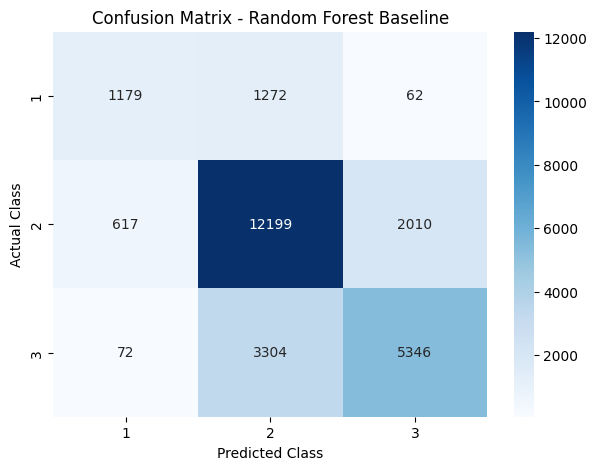

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion matrix for the best model
cm = confusion_matrix(y_val, y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3],
    yticklabels=[1, 2, 3]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Random Forest Baseline")
plt.show()

**Feature Importance**

In [18]:
# Feature importance from the best Random Forest model

feature_importance = pd.DataFrame({
    "Feature": X_train_original.columns,
    "Importance": rf_baseline.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Most Important Features:")
display(feature_importance.head(20))

Top 20 Most Important Features:


,Feature,Importance
2,2,0.153342
0,0,0.134543
1,1,0.134538
4,4,0.122036
5,5,0.114283
6,6,0.056073
18,18,0.024966
3,3,0.016089
35,35,0.014501
8,8,0.013069


In [19]:
import pandas as pd

feature_names = pd.read_csv("feature_names.csv")["Feature"].tolist()

In [20]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_baseline.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Most Important Features:")
display(feature_importance.head(20))

Top 20 Most Important Features:


,Feature,Importance
2,num__geo_level_3_id,0.153342
0,num__geo_level_1_id,0.134543
1,num__geo_level_2_id,0.134538
4,num__age,0.122036
5,num__area_percentage,0.114283
6,num__height_percentage,0.056073
18,num__count_families,0.024966
3,num__count_floors_pre_eq,0.016089
35,cat__foundation_type_r,0.014501
8,num__has_superstructure_mud_mortar_stone,0.013069


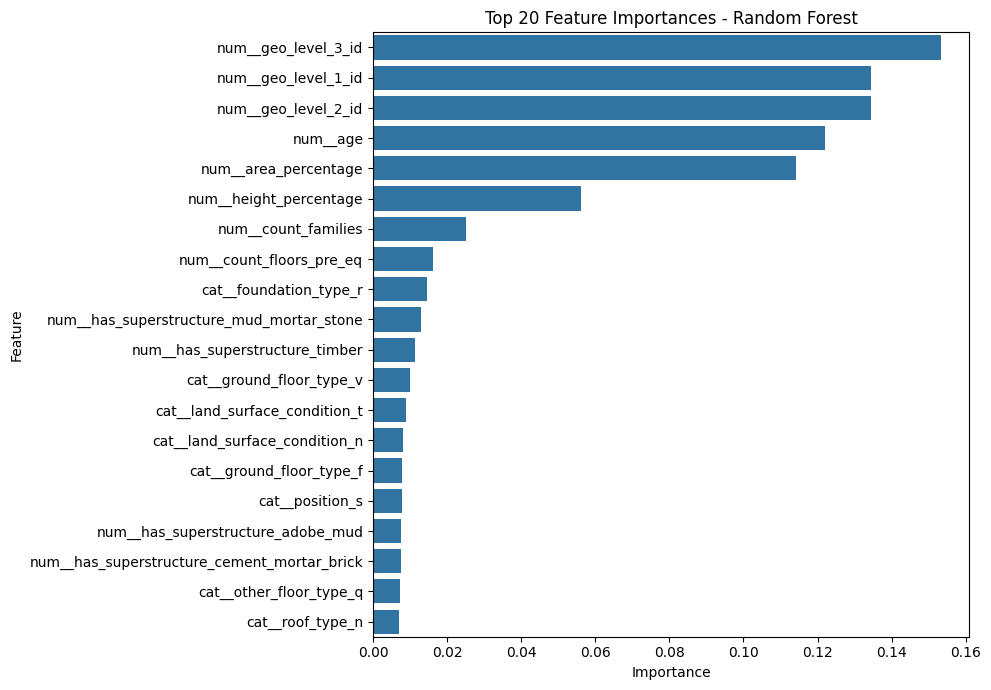

In [21]:
# Plot top 20 feature importances

top_features = feature_importance.head(20)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Tuning**

In [22]:
from sklearn.model_selection import RandomizedSearchCV

# Smaller Random Forest hyperparameter tuning

param_grid_small = {
    "n_estimators": [100, 200],
    "max_depth": [20, 30],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"]
}

rf_tuning = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_grid_small,
    n_iter=6,
    scoring="f1_macro",
    cv=2,
    verbose=2,
    random_state=42,
    n_jobs=1
)

rf_tuning.fit(X_train_original, y_train)

print("Best Parameters:")
print(rf_tuning.best_params_)

print("\nBest Cross-Validation Macro-F1:")
print(rf_tuning.best_score_)

Fitting 2 folds for each of 6 candidates, totalling 12 fits
[CV] END max_depth=20, max_features=sqrt, min_samples_split=2, n_estimators=100; total time=  12.0s
[CV] END max_depth=20, max_features=sqrt, min_samples_split=2, n_estimators=100; total time=  12.8s
[CV] END max_depth=20, max_features=sqrt, min_samples_split=2, n_estimators=200; total time=  25.2s
[CV] END max_depth=20, max_features=sqrt, min_samples_split=2, n_estimators=200; total time=  23.9s
[CV] END max_depth=20, max_features=log2, min_samples_split=2, n_estimators=200; total time=  19.9s
[CV] END max_depth=20, max_features=log2, min_samples_split=2, n_estimators=200; total time=  19.4s
[CV] END max_depth=30, max_features=log2, min_samples_split=5, n_estimators=100; total time=  12.7s
[CV] END max_depth=30, max_features=log2, min_samples_split=5, n_estimators=100; total time=  13.0s
[CV] END max_depth=30, max_features=log2, min_samples_split=2, n_estimators=200; total time=  27.0s
[CV] END max_depth=30, max_features=log2

In [23]:
# Evaluate tuned Random Forest on the validation set

best_rf = rf_tuning.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_val_original)

print("Tuned Random Forest")
print("-------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_rf_tuned))
print("Precision:", precision_score(y_val, y_pred_rf_tuned, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_rf_tuned, average="macro"))
print("Macro F1 :", f1_score(y_val, y_pred_rf_tuned, average="macro"))
print("Micro F1 :", f1_score(y_val, y_pred_rf_tuned, average="micro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf_tuned))

Tuned Random Forest
-------------------
Accuracy : 0.7253750815394651
Precision: 0.7176352265339027
Recall   : 0.6231058745293571
Macro F1 : 0.6545005922982788
Micro F1 : 0.7253750815394651

Classification Report:
              precision    recall  f1-score   support

           1       0.67      0.43      0.53      2513
           2       0.72      0.87      0.78     14826
           3       0.77      0.57      0.65      8722

    accuracy                           0.73     26061
   macro avg       0.72      0.62      0.65     26061
weighted avg       0.73      0.73      0.72     26061



In [24]:
# XGBoost hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV

xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_tuning = RandomizedSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        n_jobs=-1,
        eval_metric="mlogloss"
    ),
    param_distributions=xgb_param_grid,
    n_iter=6,
    scoring="f1_macro",
    cv=2,
    verbose=2,
    random_state=42,
    n_jobs=1
)

xgb_tuning.fit(
    X_train_original,
    y_train_xgb
)

print("Best Parameters:")
print(xgb_tuning.best_params_)

print("\nBest Cross-Validation Macro-F1:")
print(xgb_tuning.best_score_)

Fitting 2 folds for each of 6 candidates, totalling 12 fits
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=4, n_estimators=200, subsample=1.0; total time=   9.1s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=4, n_estimators=200, subsample=1.0; total time=   7.7s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=6, n_estimators=100, subsample=0.8; total time=   6.4s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=6, n_estimators=100, subsample=0.8; total time=   5.2s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=4, n_estimators=200, subsample=0.8; total time=   9.3s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=4, n_estimators=200, subsample=0.8; total time=   9.3s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=6, n_estimators=200, subsample=1.0; total time=  10.3s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=6, n_estimators=200, subsample=1.0; total time=  10.3s
[CV] END colsamp

In [25]:
# Evaluate tuned XGBoost on the validation set

best_xgb = xgb_tuning.best_estimator_

y_pred_xgb_tuned = best_xgb.predict(X_val_original) + 1

print("Tuned XGBoost")
print("-------------")
print("Accuracy :", accuracy_score(y_val, y_pred_xgb_tuned))
print("Precision:", precision_score(y_val, y_pred_xgb_tuned, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_xgb_tuned, average="macro"))
print("Macro F1 :", f1_score(y_val, y_pred_xgb_tuned, average="macro"))
print("Micro F1 :", f1_score(y_val, y_pred_xgb_tuned, average="micro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb_tuned))

Tuned XGBoost
-------------
Accuracy : 0.7202716703119604
Precision: 0.7156360604618385
Recall   : 0.6191083196071396
Macro F1 : 0.6513228395288845
Micro F1 : 0.7202716703119604

Classification Report:
              precision    recall  f1-score   support

           1       0.69      0.43      0.53      2513
           2       0.71      0.86      0.78     14826
           3       0.75      0.57      0.65      8722

    accuracy                           0.72     26061
   macro avg       0.72      0.62      0.65     26061
weighted avg       0.72      0.72      0.71     26061



In [26]:
# Logistic Regression hyperparameter tuning

lr_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

lr_tuning = RandomizedSearchCV(
    estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    param_distributions=lr_param_grid,
    n_iter=5,
    scoring="f1_macro",
    cv=2,
    verbose=2,
    random_state=42,
    n_jobs=1
)

lr_tuning.fit(X_train_original, y_train)

print("Best Parameters:")
print(lr_tuning.best_params_)

print("\nBest Cross-Validation Macro-F1:")
print(lr_tuning.best_score_)

Fitting 2 folds for each of 5 candidates, totalling 10 fits
[CV] END .............................................C=0.01; total time=   9.1s
[CV] END .............................................C=0.01; total time=   8.3s
[CV] END ..............................................C=0.1; total time=   7.7s
[CV] END ..............................................C=0.1; total time=   6.5s
[CV] END ................................................C=1; total time=   8.6s
[CV] END ................................................C=1; total time=   7.7s
[CV] END ...............................................C=10; total time=   7.9s
[CV] END ...............................................C=10; total time=   8.0s
[CV] END ..............................................C=100; total time=   8.1s
[CV] END ..............................................C=100; total time=   6.7s
Best Parameters:
{'C': 1}

Best Cross-Validation Macro-F1:
0.4646816335037418


In [27]:
# Evaluate tuned Logistic Regression

best_lr = lr_tuning.best_estimator_

y_pred_lr_tuned = best_lr.predict(X_val_original)

print("Tuned Logistic Regression")
print("-------------------------")
print("Accuracy :", accuracy_score(y_val, y_pred_lr_tuned))
print("Precision:", precision_score(y_val, y_pred_lr_tuned, average="macro"))
print("Recall   :", recall_score(y_val, y_pred_lr_tuned, average="macro"))
print("Macro F1 :", f1_score(y_val, y_pred_lr_tuned, average="macro"))
print("Micro F1 :", f1_score(y_val, y_pred_lr_tuned, average="micro"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_lr_tuned))

Tuned Logistic Regression
-------------------------
Accuracy : 0.5923410460074441
Precision: 0.5712831682880379
Recall   : 0.4554794389087962
Macro F1 : 0.4631416506947315
Micro F1 : 0.5923410460074441

Classification Report:
              precision    recall  f1-score   support

           1       0.56      0.29      0.38      2513
           2       0.60      0.87      0.71     14826
           3       0.56      0.20      0.30      8722

    accuracy                           0.59     26061
   macro avg       0.57      0.46      0.46     26061
weighted avg       0.58      0.59      0.54     26061



In [28]:
# Final comparison of original and tuned models

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "Tuned Logistic Regression",
        "Tuned Random Forest",
        "Tuned XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_pred_lr),
        accuracy_score(y_val, y_pred_rf),
        accuracy_score(y_val, y_pred_xgb),
        accuracy_score(y_val, y_pred_lr_tuned),
        accuracy_score(y_val, y_pred_rf_tuned),
        accuracy_score(y_val, y_pred_xgb_tuned)
    ],
    "Macro Precision": [
        precision_score(y_val, y_pred_lr, average="macro"),
        precision_score(y_val, y_pred_rf, average="macro"),
        precision_score(y_val, y_pred_xgb, average="macro"),
        precision_score(y_val, y_pred_lr_tuned, average="macro"),
        precision_score(y_val, y_pred_rf_tuned, average="macro"),
        precision_score(y_val, y_pred_xgb_tuned, average="macro")
    ],
    "Macro Recall": [
        recall_score(y_val, y_pred_lr, average="macro"),
        recall_score(y_val, y_pred_rf, average="macro"),
        recall_score(y_val, y_pred_xgb, average="macro"),
        recall_score(y_val, y_pred_lr_tuned, average="macro"),
        recall_score(y_val, y_pred_rf_tuned, average="macro"),
        recall_score(y_val, y_pred_xgb_tuned, average="macro")
    ],
    "Macro F1": [
        f1_score(y_val, y_pred_lr, average="macro"),
        f1_score(y_val, y_pred_rf, average="macro"),
        f1_score(y_val, y_pred_xgb, average="macro"),
        f1_score(y_val, y_pred_lr_tuned, average="macro"),
        f1_score(y_val, y_pred_rf_tuned, average="macro"),
        f1_score(y_val, y_pred_xgb_tuned, average="macro")
    ],
    "Micro F1": [
        f1_score(y_val, y_pred_lr, average="micro"),
        f1_score(y_val, y_pred_rf, average="micro"),
        f1_score(y_val, y_pred_xgb, average="micro"),
        f1_score(y_val, y_pred_lr_tuned, average="micro"),
        f1_score(y_val, y_pred_rf_tuned, average="micro"),
        f1_score(y_val, y_pred_xgb_tuned, average="micro")
    ]
})

final_results = final_results.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

final_results

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro F1
0,Random Forest,0.718468,0.693016,0.634968,0.657584,0.718468
1,Tuned Random Forest,0.725375,0.717635,0.623106,0.654501,0.725375
2,XGBoost,0.721461,0.716034,0.620025,0.652191,0.721461
3,Tuned XGBoost,0.720272,0.715636,0.619108,0.651323,0.720272
4,Logistic Regression,0.592341,0.571283,0.455479,0.463142,0.592341
5,Tuned Logistic Regression,0.592341,0.571283,0.455479,0.463142,0.592341


In [29]:
# Final model: Random Forest Baseline

final_model = rf_baseline

# Generate predictions for the test dataset
test_predictions = final_model.predict(X_test_original)

print("Test predictions generated successfully.")
print("Number of predictions:", len(test_predictions))
print("Prediction classes:", np.unique(test_predictions))

Test predictions generated successfully.
Number of predictions: 86868
Prediction classes: [1 2 3]


In [30]:
print("First 10 test indices:")
print(X_test_original.index[:10].tolist())

print("\nDoes X_test_original contain building_id?")
print("building_id" in X_test_original.columns)

print("\nNumber of test rows:")
print(len(X_test_original))

First 10 test indices:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Does X_test_original contain building_id?
False

Number of test rows:
86868


In [31]:
# Load original test data to recover building_id

test_values = pd.read_csv("test_values.csv")

print(test_values.head())
print("\nShape:", test_values.shape)
print("\nColumns:", test_values.columns.tolist()[:10])

   building_id  geo_level_1_id  geo_level_2_id  geo_level_3_id  \
0       300051              17             596           11307   
1        99355               6             141           11987   
2       890251              22              19           10044   
3       745817              26              39             633   
4       421793              17             289            7970   

   count_floors_pre_eq  age  area_percentage  height_percentage  \
0                    3   20                7                  6   
1                    2   25               13                  5   
2                    2    5                4                  5   
3                    1    0               19                  3   
4                    3   15                8                  7   

  land_surface_condition foundation_type  ... has_secondary_use_agriculture  \
0                      t               r  ...                             0   
1                      t               r  

In [32]:
# Create submission using the original building IDs

submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_predictions
})

print("Submission shape:", submission.shape)
print("\nFirst 5 rows:")
display(submission.head())

print("\nLast 5 rows:")
display(submission.tail())

Submission shape: (86868, 2)

First 5 rows:


,building_id,damage_grade
0,300051,2
1,99355,2
2,890251,2
3,745817,1
4,421793,3



Last 5 rows:


,building_id,damage_grade
86863,310028,2
86864,663567,2
86865,1049160,2
86866,442785,2
86867,501372,1


In [33]:
# Save final submission file

submission.to_csv("earthquake_damage_submission.csv", index=False)

print("Submission file saved successfully.")
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())

Submission file saved successfully.
Rows: 86868
Columns: ['building_id', 'damage_grade']
